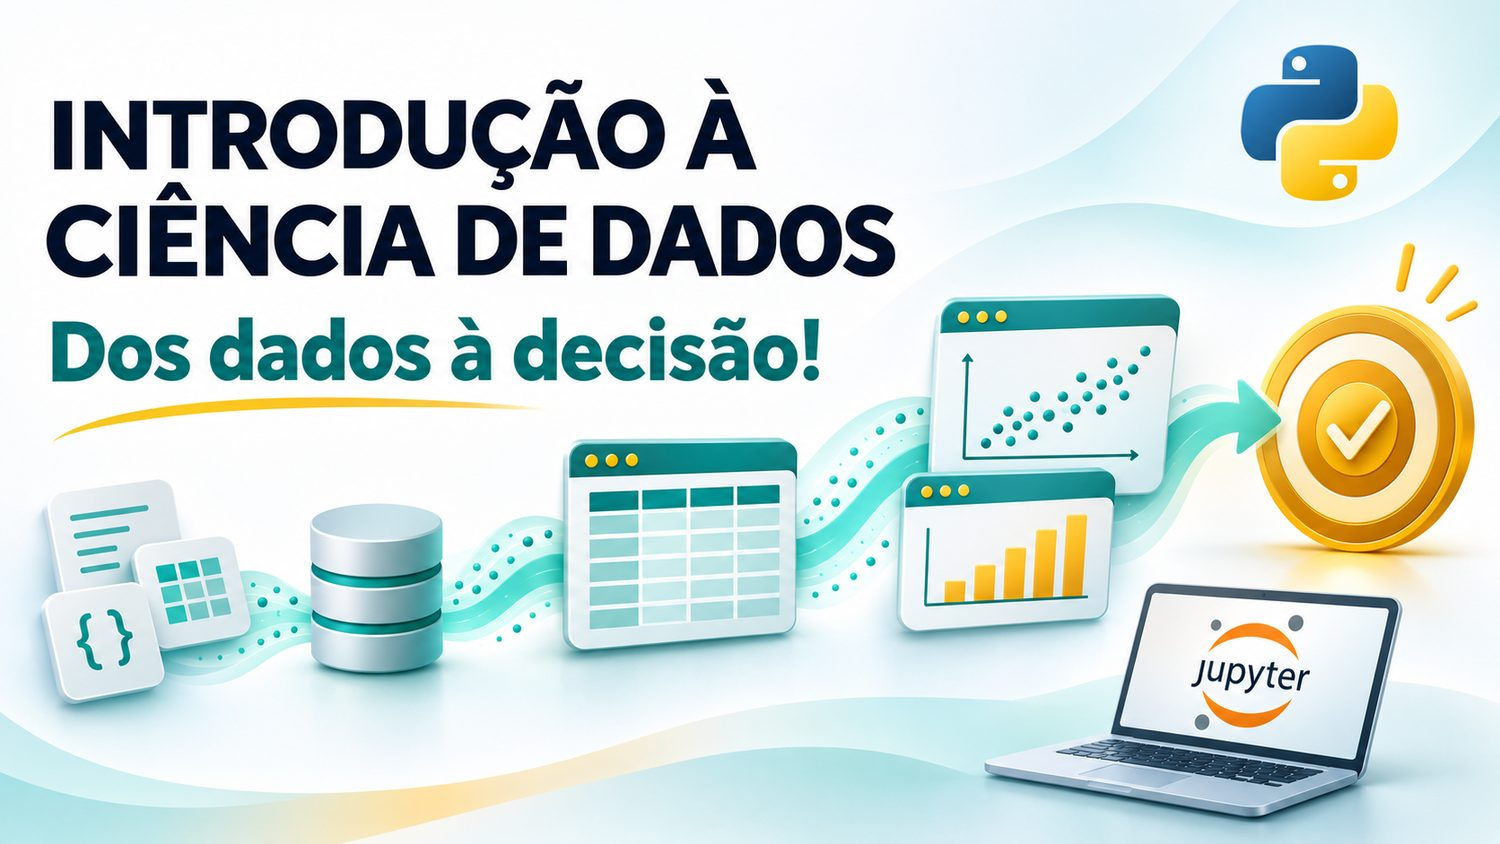

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/02_Treino_Teste_e_Linha_de_Base.ipynb)

# Capítulo 2 – Treino, teste e linha de base

Um modelo que decora os exemplos tem erro zero nos dados que já viu. Para saber quanto vale num carro novo, é preciso guardar carros que ele nunca veja. Este capítulo trata da regra mais importante da modelação: separar os dados em treino e teste, e comparar sempre com uma linha de base.

> **Objetivos:** explicar porque o erro de treino é otimista; dividir os dados em treino e teste; estratificar a divisão; construir linhas de base para regressão e para classificação; usar um conjunto de validação para fazer escolhas; perceber porque o teste só se usa uma vez; reconhecer quando a divisão ao acaso não serve.

**Pré-requisitos:** capítulo 1 deste módulo, e o capítulo 3 do módulo 1. A sintaxe está em [Scikit-Learn: fundamentos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_03_ScikitLearn_Fundamentos.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


In [3]:
# Neste capítulo usamos só os carros sem valores em falta e três atributos numéricos.
# Os valores em falta, as escalas e as categorias são os temas dos capítulos 3, 4 e 5.
dados = carros.dropna(subset=["km", "potencia_cv"]).assign(idade=lambda t: 2026 - t["ano"]).reset_index(drop=True)
atributos = ["idade", "km", "potencia_cv"]
X, y = dados[atributos], dados["preco"]
print(X.shape)

(2618, 3)


## O erro de treino engana

O modelo dos **vizinhos mais próximos** (KNN, que estudaremos no módulo 6) prevê o preço de um carro a partir dos carros mais parecidos que conhece. Com um só vizinho, o carro mais parecido com um carro de treino é ele próprio.

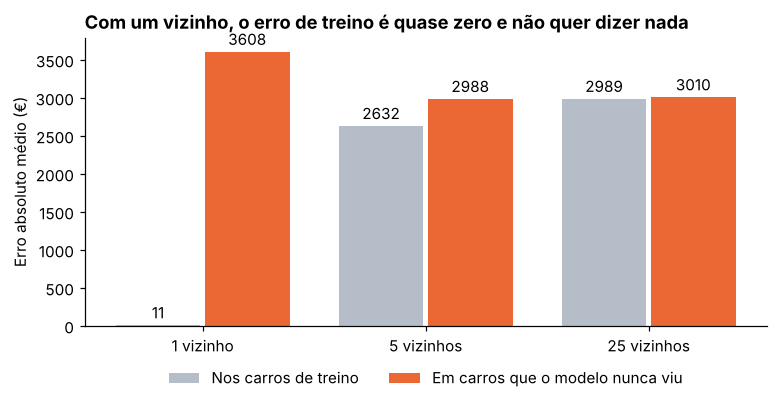

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)

resultados = {}
for k in [1, 5, 25]:
    modelo = KNeighborsRegressor(n_neighbors=k).fit(X_treino, y_treino)
    resultados[f"{k} vizinho" + ("s" if k > 1 else "")] = (mean_absolute_error(y_treino, modelo.predict(X_treino)),
                                                             mean_absolute_error(y_teste, modelo.predict(X_teste)))

nomes = list(resultados)
x = np.arange(len(nomes))
fig, ax = plt.subplots(figsize=(8, 3.4))
b1 = ax.bar(x - 0.2, [resultados[n][0] for n in nomes], 0.38, color=CINZA, label="Nos carros de treino")
b2 = ax.bar(x + 0.2, [resultados[n][1] for n in nomes], 0.38, color=LARANJA, label="Em carros que o modelo nunca viu")
ax.bar_label(b1, fmt="%.0f", padding=2)
ax.bar_label(b2, fmt="%.0f", padding=2)
ax.set_xticks(x, nomes)
ax.set_ylabel("Erro absoluto médio (€)")
ax.set_title("Com um vizinho, o erro de treino é quase zero e não quer dizer nada")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

Com um vizinho, o modelo decora: erro quase nulo no treino, e o pior dos três em carros novos. Quem escolhesse o modelo pelo erro de treino escolhia o pior.

A diferença entre as duas barras é o sinal de **sobreajuste** (*overfitting*): o modelo ajustou-se aos pormenores dos exemplos, incluindo o acaso, em vez de aprender a regra geral. Voltaremos a ele no módulo 6.

> **O desempenho de um modelo mede-se sempre em dados que não participaram no treino.**

## Dividir em treino e teste

A solução é separar os dados em duas partes **antes de fazer qualquer outra coisa**.

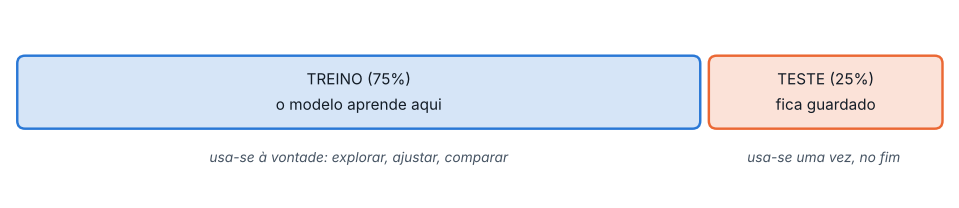

In [5]:
fig, ax = tela(12, 2.4, (11, 2.2))
caixa(ax, 0.1, 0.9, 8.7, 0.9, "TREINO (75%)\no modelo aprende aqui", AZUL, 10)
caixa(ax, 8.95, 0.9, 2.95, 0.9, "TESTE (25%)\nfica guardado", LARANJA, 10)
ax.text(4.45, 0.45, "usa-se à vontade: explorar, ajustar, comparar", ha="center", fontsize=9, color="#465463", style="italic")
ax.text(10.4, 0.45, "usa-se uma vez, no fim", ha="center", fontsize=9, color="#465463", style="italic")
plt.show()

In [6]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)
print(f"Treino: {len(X_treino)} carros | Teste: {len(X_teste)} carros")
print(f"Preço mediano no treino: {y_treino.median():.0f} € | no teste: {y_teste.median():.0f} €")

Treino: 1963 carros | Teste: 655 carros
Preço mediano no treino: 5630 € | no teste: 5900 €


Três pormenores da função `train_test_split`:

- **baralha** as linhas antes de dividir. Se os dados estiverem ordenados (por data, por preço), cortar simplesmente o fim daria um teste diferente do treino;
- `test_size=0.25` reserva um quarto para teste. Valores entre 20% e 30% são habituais; com muitos dados, pode ser menos;
- `random_state` fixa o sorteio, para a divisão ser sempre a mesma (módulo 1, capítulo 4).

As duas partes devem parecer-se. As medianas acima são próximas, como se espera de um sorteio com tantos carros.

### Estratificar

Em classificação, convém que as classes tenham a mesma proporção no treino e no teste. Com poucos dados ou classes raras, o sorteio simples pode falhar por muito. A opção `stratify` garante as proporções.

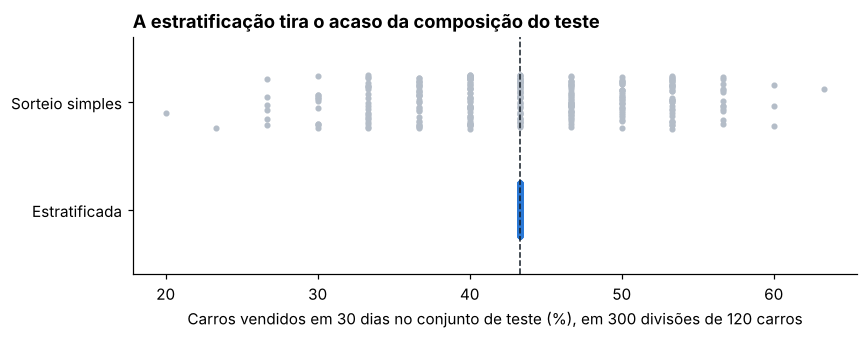

In [7]:
alvo = dados["vendido_30_dias"]
pequena = dados.sample(120, random_state=1)
simples, estratificada = [], []
for semente in range(300):
    _, teste_s = train_test_split(pequena["vendido_30_dias"], test_size=0.25, random_state=semente)
    _, teste_e = train_test_split(pequena["vendido_30_dias"], test_size=0.25, random_state=semente, stratify=pequena["vendido_30_dias"])
    simples.append(teste_s.mean() * 100)
    estratificada.append(teste_e.mean() * 100)

fig, ax = plt.subplots(figsize=(8.5, 2.8))
rng = np.random.default_rng(0)
ax.scatter(simples, rng.uniform(0.75, 1.25, 300), s=9, color=CINZA)
ax.scatter(estratificada, rng.uniform(-0.25, 0.25, 300), s=9, color=AZUL)
ax.axvline(pequena["vendido_30_dias"].mean() * 100, color=TINTA, ls="--", lw=1)
ax.set_yticks([0, 1], ["Estratificada", "Sorteio simples"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Carros vendidos em 30 dias no conjunto de teste (%), em 300 divisões de 120 carros")
ax.set_title("A estratificação tira o acaso da composição do teste")
plt.show()

Com sorteio simples, a percentagem de carros vendidos no teste vai de menos de 30% a mais de 60%, quando na amostra é a da linha tracejada. Um modelo avaliado num teste com 30% de vendidos e outro avaliado num com 60% não são comparáveis. A estratificação põe todos os testes praticamente no mesmo valor.

## A linha de base

Um erro de 2 000 € é bom ou mau? Sozinho, o número não diz nada. É preciso compará-lo com o que se consegue **sem modelo** (módulo 1, capítulo 3).

| Tarefa | Linha de base mais simples | No scikit-learn |
| --- | --- | --- |
| Regressão | Prever sempre a mediana (ou a média) do treino | `DummyRegressor(strategy="median")` |
| Classificação | Prever sempre a classe mais frequente | `DummyClassifier(strategy="most_frequent")` |
| Qualquer uma | A regra que a organização usa hoje | o que existir |

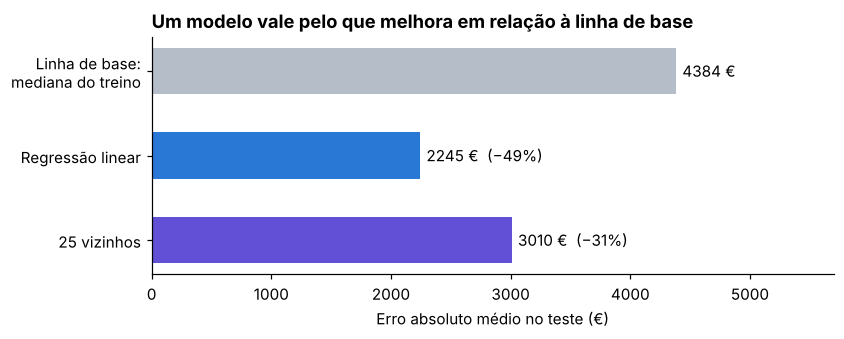

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

modelos = {"Linha de base:\nmediana do treino": DummyRegressor(strategy="median"),
           "Regressão linear": LinearRegression(),
           "25 vizinhos": KNeighborsRegressor(n_neighbors=25)}
erros = {nome: mean_absolute_error(y_teste, m.fit(X_treino, y_treino).predict(X_teste)) for nome, m in modelos.items()}

fig, ax = plt.subplots(figsize=(8, 2.8))
barras = ax.barh(list(erros), list(erros.values()), color=[CINZA, AZUL, VIOLETA], height=0.55)
base = erros["Linha de base:\nmediana do treino"]
ax.bar_label(barras, labels=[f"{v:.0f} €" + ("" if v == base else f"  (−{1 - v / base:.0%})") for v in erros.values()], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, base * 1.3)
ax.set_xlabel("Erro absoluto médio no teste (€)")
ax.set_title("Um modelo vale pelo que melhora em relação à linha de base")
plt.show()

A linha de base propõe o mesmo preço para todos os carros e erra, em média, mais de 4 000 €. Os dois modelos reduzem esse erro entre um terço e metade. É esta redução que se apresenta, e não o erro isolado.

A mediana do treino é a linha de base mais fraca. A mais exigente é a prática atual: no capítulo 1, as regras escritas à mão erravam cerca de 2 300 €. Um modelo que não bata essas regras não traz nada ao stand.

## Escolher sem gastar o teste

Qual é o melhor número de vizinhos? A tentação é experimentar vários e ficar com o que der menor erro no teste. O problema é que, a partir desse momento, **o teste participou na escolha**, e deixou de ser uma medida independente.

A solução é dividir o treino outra vez, e guardar uma terceira parte para as escolhas: o conjunto de **validação**.

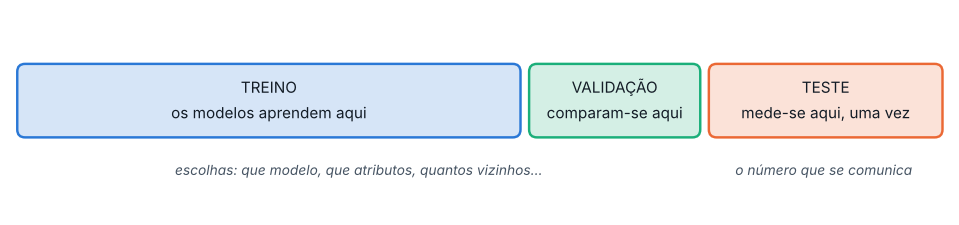

In [9]:
fig, ax = tela(12, 2.6, (11, 2.4))
caixa(ax, 0.1, 1.0, 6.4, 0.9, "TREINO\nos modelos aprendem aqui", AZUL, 10)
caixa(ax, 6.65, 1.0, 2.15, 0.9, "VALIDAÇÃO\ncomparam-se aqui", VERDE, 10)
caixa(ax, 8.95, 1.0, 2.95, 0.9, "TESTE\nmede-se aqui, uma vez", LARANJA, 10)
ax.text(4.45, 0.5, "escolhas: que modelo, que atributos, quantos vizinhos…", ha="center", fontsize=9, color="#465463", style="italic")
ax.text(10.4, 0.5, "o número que se comunica", ha="center", fontsize=9, color="#465463", style="italic")
plt.show()

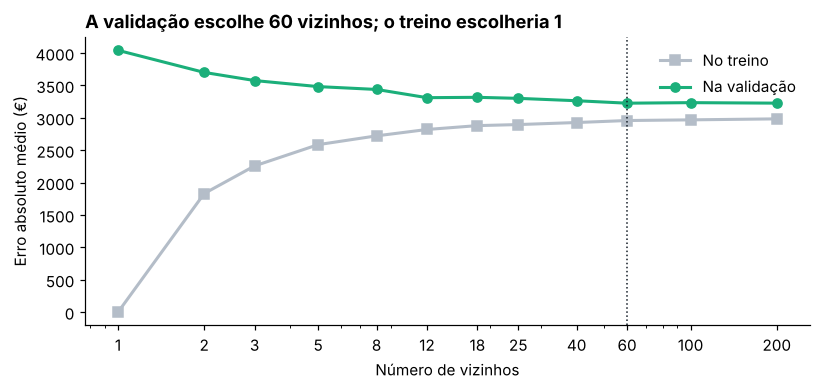

Erro no teste do modelo escolhido (60 vizinhos): 2994 €


In [10]:
X_ajuste, X_validacao, y_ajuste, y_validacao = train_test_split(X_treino, y_treino, test_size=0.25, random_state=0)

vizinhos = [1, 2, 3, 5, 8, 12, 18, 25, 40, 60, 100, 200]
erro_ajuste, erro_validacao = [], []
for k in vizinhos:
    modelo = KNeighborsRegressor(n_neighbors=k).fit(X_ajuste, y_ajuste)
    erro_ajuste.append(mean_absolute_error(y_ajuste, modelo.predict(X_ajuste)))
    erro_validacao.append(mean_absolute_error(y_validacao, modelo.predict(X_validacao)))
melhor_k = vizinhos[int(np.argmin(erro_validacao))]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(vizinhos, erro_ajuste, color=CINZA, lw=2, marker="s", label="No treino")
ax.plot(vizinhos, erro_validacao, color=VERDE, lw=2, marker="o", label="Na validação")
ax.axvline(melhor_k, color=TINTA, ls=":", lw=1)
ax.set_xscale("log")
ax.set_xticks(vizinhos, [str(k) for k in vizinhos])
ax.set_xlabel("Número de vizinhos")
ax.set_ylabel("Erro absoluto médio (€)")
ax.set_title(f"A validação escolhe {melhor_k} vizinhos; o treino escolheria 1")
ax.legend(frameon=False)
plt.show()

final = KNeighborsRegressor(n_neighbors=melhor_k).fit(X_treino, y_treino)        # treina-se de novo com o treino todo
print(f"Erro no teste do modelo escolhido ({melhor_k} vizinhos): {mean_absolute_error(y_teste, final.predict(X_teste)):.0f} €")

O erro de treino desce sempre que se reduz o número de vizinhos. O erro de validação faz o contrário: é mais alto com poucos vizinhos, porque o modelo decora, desce à medida que se juntam mais, e a partir de certo ponto deixa de melhorar.

Repara que o KNN está a perder para a regressão linear. A razão é que os três atributos têm escalas muito diferentes (os quilómetros valem dezenas de milhares, a idade vale unidades), e isso estraga as distâncias. É o tema do capítulo 4.

O procedimento completo tem três tempos:

1. **treinar** vários candidatos na parte de treino;
2. **comparar** os candidatos na validação e escolher um;
3. **medir** o escolhido no teste, uma única vez, e é esse o número que se comunica.

### Porque o teste só se usa uma vez

Para ver o perigo de escolher pelo teste, vamos exagerar. A célula seguinte cria 500 «modelos» que não sabem nada: cada um propõe os preços dos carros de treino, baralhados ao acaso.

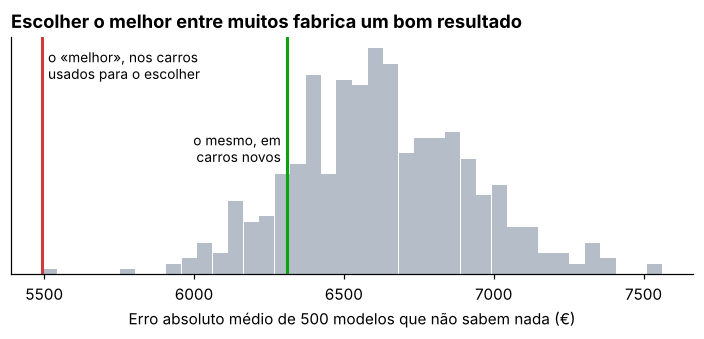

In [11]:
rng = np.random.default_rng(1)
X_novos, y_novos = X_teste.iloc[:300], y_teste.iloc[:300]             # fingimos que estes carros chegam mais tarde
y_escolha = y_teste.iloc[300:]

erros_escolha, erros_novos = [], []
for _ in range(500):
    palpites = rng.choice(y_treino.to_numpy(), len(y_teste))           # previsões sem qualquer relação com os carros
    erros_escolha.append(mean_absolute_error(y_escolha, palpites[300:]))
    erros_novos.append(mean_absolute_error(y_novos, palpites[:300]))
vencedor = int(np.argmin(erros_escolha))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(erros_escolha, bins=40, color=CINZA)
ax.axvline(erros_escolha[vencedor], color=MAU, lw=2)
ax.axvline(erros_novos[vencedor], color=BOM, lw=2)
topo = ax.get_ylim()[1]
ax.text(erros_escolha[vencedor] + 20, topo * 0.95, "o «melhor», nos carros\nusados para o escolher", va="top", fontsize=9)
ax.text(erros_novos[vencedor] - 20, topo * 0.6, "o mesmo, em\ncarros novos", va="top", ha="right", fontsize=9)
ax.set_xlabel("Erro absoluto médio de 500 modelos que não sabem nada (€)")
ax.set_yticks([])
ax.set_title("Escolher o melhor entre muitos fabrica um bom resultado")
plt.show()

Nenhum dos 500 sabe nada, mas o «melhor» parece claramente melhor do que os outros nos carros que serviram para o escolher. Em carros novos, volta para o meio da distribuição. O bom resultado era sorte, e escolher pelo teste é uma forma de a selecionar. É o problema das comparações múltiplas (módulo 1, capítulo 5), com outro nome.

> **Cada vez que se olha para o teste para tomar uma decisão, o teste vale um pouco menos.** Se for usado muitas vezes, deixa de medir o que quer que seja.

## Uma só divisão é uma amostra

O erro de teste também depende do sorteio. Vamos repetir a divisão 200 vezes com o mesmo modelo.

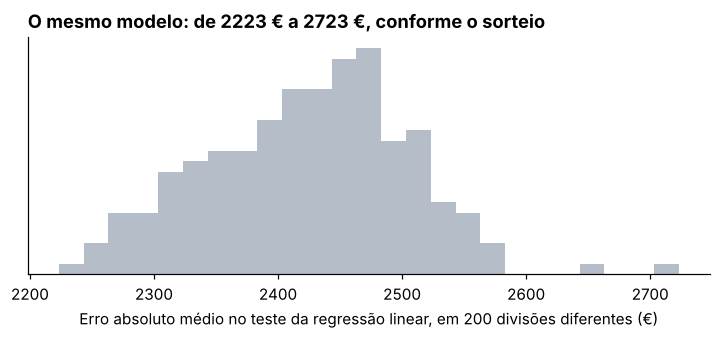

In [12]:
erros_repetidos = []
for semente in range(200):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, random_state=semente)
    erros_repetidos.append(mean_absolute_error(yb, LinearRegression().fit(Xa, ya).predict(Xb)))
erros_repetidos = np.array(erros_repetidos)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(erros_repetidos, bins=25, color=CINZA)
ax.set_xlabel("Erro absoluto médio no teste da regressão linear, em 200 divisões diferentes (€)")
ax.set_yticks([])
ax.set_title(f"O mesmo modelo: de {erros_repetidos.min():.0f} € a {erros_repetidos.max():.0f} €, conforme o sorteio")
plt.show()

O erro de teste é uma **estimativa**, com a sua incerteza (módulo 1, capítulo 5). Uma diferença de 30 € entre dois modelos, medida numa só divisão, pode ser só o sorteio.

A forma habitual de reduzir esta incerteza é a **validação cruzada**: repetir a divisão várias vezes de forma organizada e fazer a média. É um dos temas do módulo 6.

## Quando não se divide ao acaso

A divisão ao acaso pressupõe que as observações são independentes e que o futuro se parece com o passado. Há três situações comuns em que isso falha.

| Situação | Problema | Como dividir |
| --- | --- | --- |
| **Dados com tempo** | Treinar com o futuro para prever o passado é impossível na prática | Treino antes, teste depois (módulo 3, capítulo 6) |
| **Grupos** | O mesmo carro anunciado três vezes fica no treino e no teste | Todas as linhas do mesmo grupo do mesmo lado (`GroupShuffleSplit`) |
| **Duplicados** | Linhas repetidas põem a resposta do teste no treino | Remover os duplicados antes de dividir |

Em todas, o resultado de uma divisão ao acaso é um erro de teste demasiado baixo, que só se descobre quando o modelo já está a ser usado.

> **A divisão deve imitar a forma como o modelo vai ser usado.** Se vai prever carros que chegam no próximo mês, testa-se em carros que chegaram depois dos de treino.

## Exercícios

### `Exercício 1` – Certo ou errado?

1. «O modelo tem 99% de acerto nos dados de treino, por isso está pronto.»
2. «Testei dez modelos no conjunto de teste e escolhi o melhor. O erro desse é o que vou comunicar.»
3. «Com 200 observações e 3% de casos positivos, uso `stratify`.»
4. «Tenho medições do mesmo paciente em vinte dias diferentes; divido as linhas ao acaso.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Errado: o erro de treino não diz como o modelo se porta em dados novos.
2. Errado: o teste participou na escolha, por isso o erro do vencedor é otimista. A escolha faz-se na validação.
3. Certo: sem estratificar, o teste de 50 observações podia ficar com zero ou com quatro positivos.
4. Errado: as medições do mesmo paciente são parecidas. Todas as linhas de cada paciente têm de ficar do mesmo lado.

</details>

### `Exercício 2` – Uma linha de base para a classificação

Divide os dados (com estratificação) para prever `vendido_30_dias` a partir dos três atributos. Calcula a exatidão de um `DummyClassifier` com a estratégia `most_frequent` e a de uma `LogisticRegression`. O modelo bate a linha de base?

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

Xa, Xb, ya, yb = train_test_split(X, dados["vendido_30_dias"], test_size=0.25, random_state=0, stratify=dados["vendido_30_dias"])
base = DummyClassifier(strategy="most_frequent").fit(Xa, ya).score(Xb, yb)
modelo = LogisticRegression(max_iter=5000).fit(Xa, ya).score(Xb, yb)
print(f"Linha de base: {base:.1%} | regressão logística: {modelo:.1%}")
```

A linha de base acerta em cerca de 56% dos casos (diz sempre «não vende»). O modelo fica poucos pontos acima: a idade, os quilómetros e a potência dizem pouco sobre a venda. Faltam-lhe o estado e o segmento, que são categorias (capítulo 5).

</details>

### `Exercício 3` – O tamanho do teste

Repete a experiência das 200 divisões com `test_size` de 0,05, 0,25 e 0,5. Como muda a dispersão do erro de teste? O que se ganha e o que se perde com um teste maior?

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for fracao in [0.05, 0.25, 0.5]:
    e = []
    for semente in range(200):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=fracao, random_state=semente)
        e.append(mean_absolute_error(yb, LinearRegression().fit(Xa, ya).predict(Xb)))
    print(f"teste de {fracao:.0%}: média {np.mean(e):.0f} €, desvio {np.std(e):.0f} €")
```

Com um teste pequeno, o erro medido varia muito de sorteio para sorteio: a estimativa é imprecisa. Com um teste grande, a estimativa é mais estável, mas sobram menos dados para treinar. Com um modelo simples e alguns milhares de linhas, como aqui, o treino quase não sofre; com poucos dados ou modelos complexos, sofre bastante.

</details>

### `Exercício 4` – Fabricar uma fuga

Duplica 20% das linhas de `dados` (como se alguns carros tivessem sido anunciados duas vezes) e só depois divide ao acaso. Compara o erro de teste de um KNN com 1 vizinho com o que obtiveste sem duplicados. O que aconteceu?

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
duplicado = pd.concat([dados, dados.sample(frac=0.2, random_state=0)], ignore_index=True)
Xa, Xb, ya, yb = train_test_split(duplicado[atributos], duplicado["preco"], test_size=0.25, random_state=0)
print(round(mean_absolute_error(yb, KNeighborsRegressor(n_neighbors=1).fit(Xa, ya).predict(Xb))))
```

O erro de teste baixa bastante. Uma parte dos carros de teste tem uma cópia exata no treino, e o modelo de um vizinho limita-se a devolvê-la. O modelo não ficou melhor: o teste é que deixou de ser independente. Num carro realmente novo, o erro seria o de antes.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar porque o erro de treino é otimista.
- [ ] Sei dividir os dados em treino e teste, e fixar o sorteio.
- [ ] Sei quando e porquê estratificar.
- [ ] Sei construir uma linha de base e apresentar um resultado em relação a ela.
- [ ] Sei para que serve o conjunto de validação.
- [ ] Sei porque o teste só se usa uma vez.
- [ ] Sei que o erro de teste é uma estimativa, com incerteza.
- [ ] Sei três situações em que a divisão ao acaso dá um resultado enganador.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/cross_validation.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://en.wikipedia.org/wiki/Training,_validation,_and_test_data_sets